In [1]:

import numpy as np
import matplotlib.pyplot as plt
import os
import torch
import pandas as pd
import adabmDCA as dca
from annadca.rbm import get_rbm
from annadca.dataset import annaDataset
from annadca.utils.analysis import get_eigenvalues_history
import seaborn as sns
sns.set(style="whitegrid")

plt.rcParams.update({'font.size': 14,
                     'text.usetex': True})

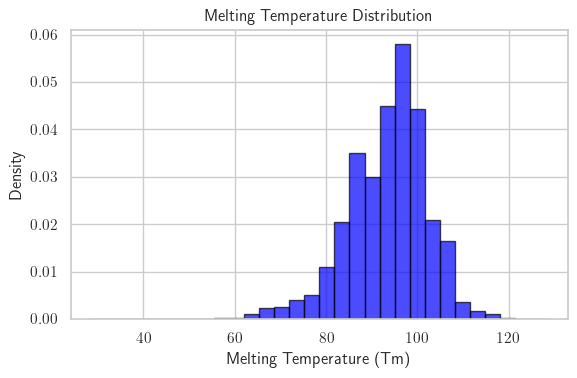

In [2]:
fname_data = "../data/tRNA/RF00005.csv"
df = pd.read_csv(fname_data)
tms = df["Tm"].to_numpy()

plt.figure(figsize=(6,4))
plt.hist(tms, bins=30, density=True, alpha=0.7, color='blue', edgecolor='black')
plt.title("Melting Temperature Distribution")
plt.xlabel("Melting Temperature (Tm)")
plt.ylabel("Density")
plt.grid(True)
plt.tight_layout()

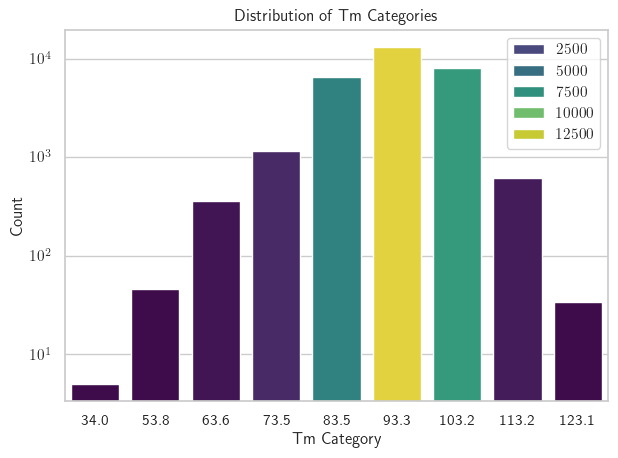

In [9]:
# categorize Tm into 10 categories with equal width
quantiles = pd.cut(tms, bins=10, labels=False)
# map the categories to the midpoint of each bin
bin_edges = np.linspace(tms.min(), tms.max(), 11)
tm_categories = (bin_edges[:-1] + bin_edges[1:]) / 2
tm_categories = tm_categories[quantiles]
uq, counts = np.unique(tm_categories, return_counts=True)
sns.barplot(x=uq, y=counts, hue=counts, palette="viridis")
plt.xlabel("Tm Category")
plt.ylabel("Count")
plt.yscale("log")
# set precision of xticks
plt.xticks(ticks=np.arange(0, 9), labels=[f"{i:.1f}" for i in uq])
plt.title("Distribution of Tm Categories")
plt.tight_layout()

In [11]:
df["categ_label"] = pd.cut(df["Tm"], bins=10, labels=False)
df.to_csv(fname_data, index=False)

In [12]:
categ_to_mid = {i: (bin_edges[i] + bin_edges[i+1]) / 2 for i in range(10)}

### Analysis


In [14]:
fname_all = "../data/tRNA/RF00005.csv"
checkpoint_dir = "../models/tRNA/RBM/relu_cat/RBM_checkpoints"
fname_model = os.path.join(checkpoint_dir, "model_update_10000.pt")

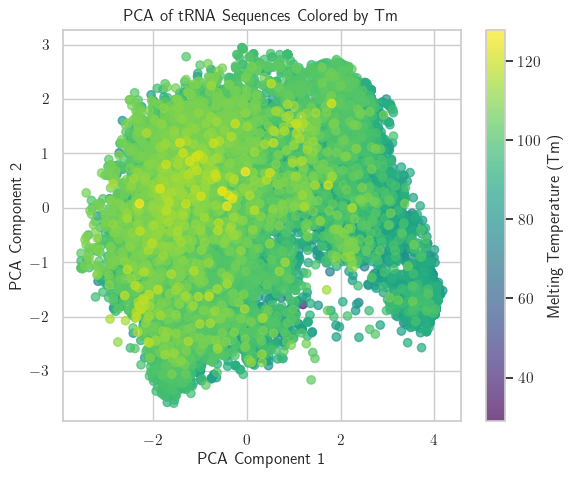

In [ ]:
from adabmDCA import encode_sequence

tokens = dca.get_tokens("rna")
df = pd.read_csv(fname_all)
mask = ~df["binary_label"].isna()
df = df[mask].reset_index(drop=True)
mask = []
for seq in df["sequence"]:
    if not all(c in tokens for c in seq):
        mask.append(False)
    else:
        mask.append(True)
df = df[mask].reset_index(drop=True)

# sort entries by Tm
df = df.sort_values(by="Tm").reset_index(drop=True)

data = encode_sequence(df["sequence"].to_list(), tokens)
data_oh = np.eye(len(tokens))[data].reshape(len(data), -1)

from sklearn.decomposition import PCA
pca = PCA(n_components=2)
data_pca = pca.fit_transform(data_oh)
label = df["Tm"].to_numpy()

plt.figure(figsize=(6,5))
scatter = plt.scatter(data_pca[:,0], data_pca[:,1], c=label, cmap='viridis', alpha=0.7)
plt.colorbar(scatter, label='Melting Temperature (Tm)')
plt.title('PCA of tRNA Sequences Colored by Tm')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.grid(True)
plt.tight_layout()
plt.show()

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
dtype = torch.float32

In [5]:
# Import dataset
dataset = annaDataset(
    path_data=fname_all,
    column_names="header",
    column_sequences="sequence",
    column_labels="categ_label",
    alphabet=tokens,
    path_weights=None,
    no_reweighting=False,
    continuous_labels=False,
    is_binary=False,
    device=device,
    dtype=dtype,
)

Filtered out 27 sequences with unknown letters. Remaining sequences: 29973.


### Logistic regression

In [6]:
dataset.to_label(dataset.labels_one_hot)

array([6, 7, 7, ..., 7, 6, 5], shape=(23519,))

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

X_train = dataset.data_one_hot
X_train = X_train.view(len(X_train), -1).cpu().numpy()
y_train = dataset.to_label(dataset.labels_one_hot)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
y_pred_train = model.predict(X_train)
accuracy = accuracy_score(y_train, y_pred_train)
print(f"Training accuracy: {accuracy:.4f}")

Training accuracy: 0.5935


### Import the RBM model

In [15]:
# Load the model and the chains
checkpoint = torch.load(fname_model, map_location=device)
rbm = get_rbm(
    visible_type="potts",
    hidden_type="relu",
    visible_shape=checkpoint["model_state_dict"]["weight_matrix"].shape[0:2],
    hidden_shape=checkpoint["model_state_dict"]["weight_matrix"].shape[2],
    num_classes=9,
    continuous_label=False,
)
rbm.load_state_dict(checkpoint["model_state_dict"])
rbm.to(device=device, dtype=dtype)

AnnaRBM(visible_layer=PottsLayer(shape=torch.Size([71, 5]), device=cuda:0, dtype=torch.float32), hidden_layer=ReLULayer(shape=torch.Size([500]), device=cuda:0, dtype=torch.float32), num_classes=torch.Size([9]), shape=torch.Size([71, 5, 500]))

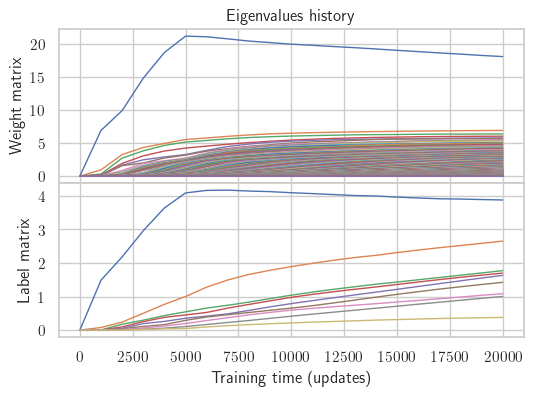

In [10]:
updates, eigenvalues = get_eigenvalues_history(checkpoint_dir, target_matrix="weight_matrix", device=device, dtype=dtype)
updates, eigenvalues_labels = get_eigenvalues_history(checkpoint_dir, target_matrix="label_matrix", device=device, dtype=dtype)

# Plot the eigenvalues history. first row is the weight matrix, second row is the label matrix.
fig, ax = plt.subplots(2, 1, figsize=(6, 4), sharex=True, gridspec_kw={'hspace': 0})
ax[0].plot(updates, eigenvalues, lw=1)
ax[1].plot(updates, eigenvalues_labels, lw=1)
ax[1].set_xlabel("Training time (updates)")
ax[0].set_ylabel("Weight matrix")
ax[1].set_ylabel("Label matrix")
ax[0].set_title("Eigenvalues history");

In [16]:
X_train = dataset.data_one_hot
y_train = dataset.to_label(dataset.labels_one_hot)
y_pred_rbm = dataset.to_label(rbm.predict_labels(X_train))
accuracy = accuracy_score(y_train, y_pred_rbm)
print(f"Training accuracy RBM: {accuracy:.4f}")

Training accuracy RBM: 0.2631


### Import the bmDCA model

In [12]:
from adabmDCA import load_params
from adabmDCA.statmech import compute_energy

fname_params_bmDCA = "../models/tRNA/eaDCA/aeDCA_params.dat"
params_DCA = load_params(fname_params_bmDCA, tokens=tokens, device=device, dtype=dtype)

### Compare energies on the natural data

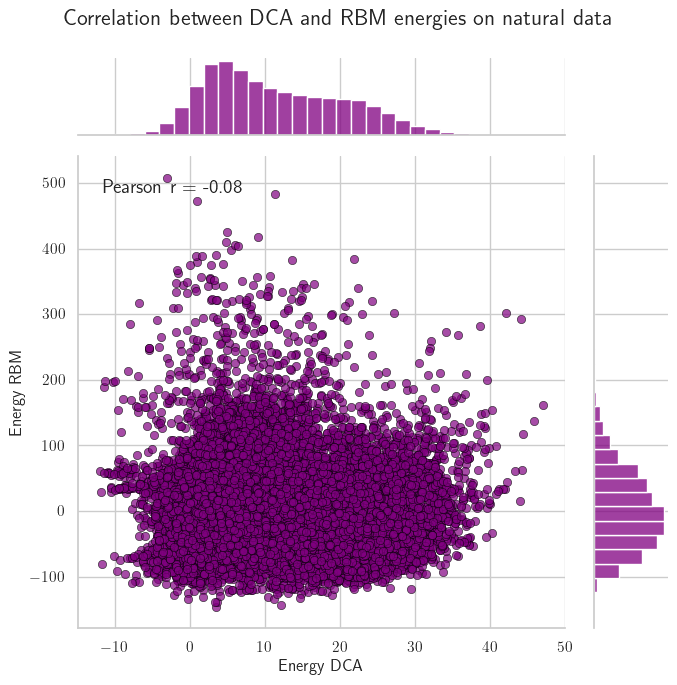

In [17]:
# compare energies on natural data
df_natural = pd.DataFrame({
    "Energy DCA": dca.compute_energy(dataset.data_one_hot, params_DCA).cpu().numpy(),
    "Energy RBM": rbm.compute_energy_visibles(dataset.data_one_hot).cpu().numpy(),
})
correlation_natural = np.corrcoef(df_natural["Energy DCA"], df_natural["Energy RBM"])[0, 1]

g = sns.jointplot(
    data=df_natural,
    x="Energy DCA",
    y="Energy RBM",
    kind="scatter",
    height=7,
    alpha=0.7,
    edgecolor='black',
    marginal_kws=dict(bins=30, fill=True),
    color='purple',
)
g.set_axis_labels("Energy DCA", "Energy RBM")
g.ax_joint.annotate(f"Pearson r = {correlation_natural:.2f}", xy=(0.05, 0.95), xycoords='axes fraction', fontsize=14, verticalalignment='top')
g.fig.suptitle("Correlation between DCA and RBM energies on natural data", fontsize=16)
g.fig.tight_layout()

### Wild-type selection

In [14]:
# Fit the PCA on all the data
from sklearn.decomposition import PCA
from adabmDCA.utils import resample_sequences

seqs_fit_pca = resample_sequences(
    dataset.data_one_hot,
    weights=dataset.weights,
    nextract=5 * len(dataset),
)
seqs_fit_pca = seqs_fit_pca.view(len(seqs_fit_pca), -1).cpu().numpy()
pca = PCA(n_components=2)
pca.fit(seqs_fit_pca)

data_proj = pca.transform(dataset.data_one_hot.view(len(dataset), -1).cpu().numpy())
labels_data = dataset.to_label(dataset.labels_one_hot)

In [15]:
mask_wt1 = dataset.to_label(dataset.labels_one_hot) == 2  # keep only sequences with low melting temperature
mask_wt2 = df_natural["Energy DCA"] < 20  # keep only sequences with low DCA energy
# only wild types without gaps
gap_idx = tokens.index('-')
mask_gap = ~torch.any(dataset.data_one_hot.argmax(2) == gap_idx, dim=1).cpu().numpy()
mask_wt =  mask_wt1 & mask_wt2 & mask_gap

wt_idx = 2  # Index of the wild-type sequence
wt = dataset.data_one_hot[mask_wt][wt_idx]
wt_proj = pca.transform(wt.view(1, -1).cpu().numpy())
wt_label = dataset[mask_wt]["label"][wt_idx]
energy_wt = compute_energy(wt.unsqueeze(0), params_DCA).item()
prob_lr_wt = model.predict_proba(wt.view(1, -1).cpu().numpy())[:, 8][0]
print(f"Wild-type label: {wt_label}")
print(f"Wild-type energy: {energy_wt}")
print(f"Wild-type LR probability: {prob_lr_wt:.4f}")

Wild-type label: tensor([0., 1., 0., 0., 0., 0., 0., 0., 0.], device='cuda:0')
Wild-type energy: 7.840843200683594
Wild-type LR probability: 0.0000


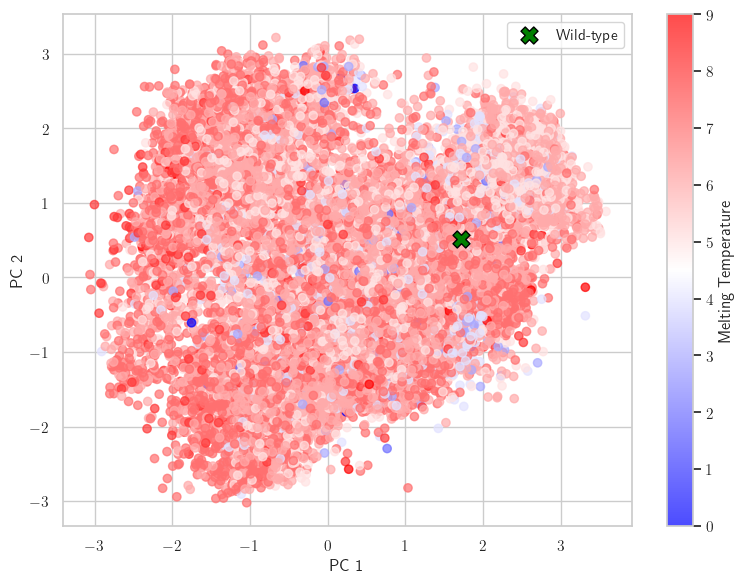

In [16]:
import seaborn as sns
sns.set(style="whitegrid")

plt.figure(figsize=(8, 6))
scatter = plt.scatter(data_proj[:, 0], data_proj[:, 1], c=labels_data, cmap='bwr', alpha=0.7)
plt.scatter(wt_proj[0, 0], wt_proj[0, 1], color='green', s=150, edgecolor='black', label='Wild-type', marker='X')
plt.legend()
plt.colorbar(scatter, label='Melting Temperature')
plt.xlabel('PC 1')
plt.ylabel('PC 2')
plt.tight_layout()

In [17]:
print(
    dca.decode_sequence(wt.unsqueeze(0).cpu().numpy(), tokens)[0]
)

GGGGAUGUAGCUCAGCGGGAGAGCGCGGCGUUCGCAAUGCCGAGGCAGGGGUUCGAUCCCCCUCAUCUCCA


### Mutate the wild type to improve thermostability

In [18]:
def plot_summary(
    samples_pca: np.ndarray,
    wild_type_pca: np.ndarray,
    data_pca: np.ndarray,
    data_labels: np.ndarray,
    distances: np.ndarray,
    energies: np.ndarray,
    sample_labels: np.ndarray,
    energy_wt: float,
    label_wt: float,
    title: str,
):
    fig, ax = plt.subplots(1, 3, figsize=(18, 5), dpi=100)
    ax = ax.flatten()

    idx = np.argsort(distances)[::-1]

    # Scatter plot PCA
    ax[0].scatter(data_pca[:, 0], data_pca[:, 1], label='Data', alpha=0.5, c=data_labels, cmap='Accent')
    sc = ax[0].scatter(samples_pca[idx, 0], samples_pca[idx, 1], c=distances[idx], cmap='tab20b', label='Samples', edgecolor='black', lw=0.5, s=30)
    ax[0].scatter(wild_type_pca[:, 0], wild_type_pca[:, 1], marker="X", s=200, c='deeppink', label='Wild Type', edgecolor='black')
    ax[0].legend()
    ax[0].set_xlabel("PCA 1")
    ax[0].set_ylabel("PCA 2")
    cbar = plt.colorbar(sc, ax=ax[0])
    cbar.set_label(r"Distance from Wild Type")
    
    # Histogram of distances
    ud, uc = np.unique(distances, return_counts=True)
    ax[1].bar(ud, uc, width=0.8, color='skyblue', alpha=0.7, edgecolor='black')
    ax[1].set_xlabel("Hamming Distance from Wild Type")
    
    # Scatter plot of Energy vs Probability
    ax[2].scatter(sample_labels[idx], energies[idx] - energy_wt, c=distances[idx], cmap="tab20b", label=f"Samples")
    ax[2].set_ylabel(r"$\Delta H_{\mathrm{gen}}$")
    ax[2].set_xlabel(r"Prob. of high Melting Temperature (LogReg)")
    ax[2].set_title(f"Phase space")
    ax[2].scatter(label_wt, 0, marker="X", s=200, c='deeppink', label='Wild Type', edgecolor='black')
    ax[2].set_xlim(0, 1)
    ax[2].legend()
    
    cbar = plt.colorbar(sc, ax=ax[2])
    cbar.set_label(r"Distance from WT")


    fig.suptitle(title, fontsize=16)
    fig.tight_layout()

In [19]:
target_label = 8  # Target melting temperature
gen_strength = 2  # Generation strength
wt_strength = 3.0  # Strength of the wild-type bias
label_strength = 3.0  # Strength of the label bias
num_steps = 10000  # Number of Gibbs steps
num_samples = 50000

rbm_biased = rbm.get_biased_model(
    gen_strength=gen_strength,
    label_strength=label_strength,
    wt_strength=wt_strength,
    wt=wt,
)
rbm_biased.visible_layer.bias[:, gap_idx] = -9999.0  # Strongly penalize gaps

chains_init = wt.repeat(num_samples, 1, 1)
targets = torch.nn.functional.one_hot(torch.full((num_samples, 1), target_label, device=device, dtype=torch.int64), num_classes=9).squeeze(1)

In [20]:
cond_samples = rbm_biased.sample_conditioned(
    gibbs_steps=num_steps,
    targets=targets,
    visible=chains_init,
)

#cond_samples = rbm_biased.sample(
#    gibbs_steps=num_steps,
#    visible=chains_init,
#)

# count the number of generated sequences that have gaps
num_gaps = torch.any(cond_samples["visible"].argmax(2) == gap_idx, dim=1).sum().item()
print(f"Number of generated sequences with gaps: {num_gaps}/{num_samples} ({num_gaps/num_samples*100:.2f}%)")

W1016 11:39:24.958000 2178258 site-packages/torch/_inductor/utils.py:1436] [0/0] Not enough SMs to use max_autotune_gemm mode


Number of generated sequences with gaps: 0/50000 (0.00%)


In [21]:
from adabmDCA.dca import get_seqid
distances = (wt.shape[0] - get_seqid(chains_init, cond_samples["visible"])).cpu().numpy()
energies = dca.compute_energy(cond_samples["visible"], params_DCA).cpu().numpy()
labels_pred_rbm = rbm.predict_labels(cond_samples["visible"])[:, target_label].cpu().numpy()
labels_pred_lr = model.predict_proba(cond_samples["visible"].view(len(cond_samples["visible"]), -1).cpu().numpy())[:, target_label]
labels_pred_rbm_wt = rbm.predict_labels(wt.view(1, *wt.shape))[:, target_label].cpu().numpy()
labels_pred_lr_wt = model.predict_proba(wt.view(1, -1).cpu().numpy())[:, target_label]
energy_wt = dca.compute_energy(wt.unsqueeze(0), params_DCA).item()

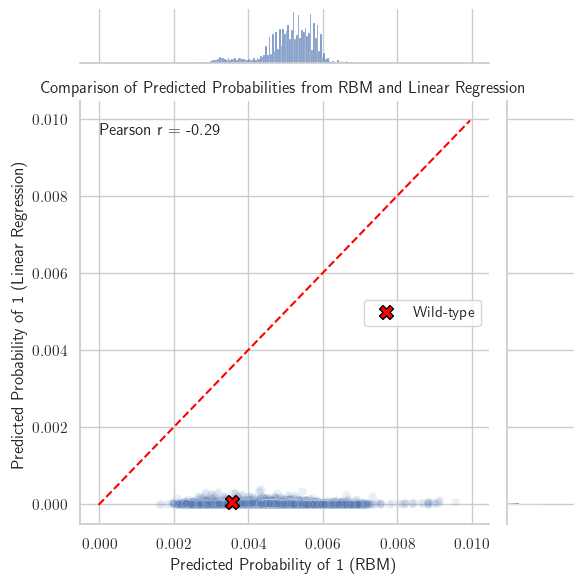

In [22]:
# Create a DataFrame for plotting
df = pd.DataFrame({'RBM Label': labels_pred_rbm, 'LR Label': labels_pred_lr})

# Jointplot with marginal histograms
g = sns.jointplot(
    data=df,
    x='RBM Label',
    y='LR Label',
    alpha=0.1,
)

# Add identity line
xlim = g.ax_joint.get_xlim()
ylim = g.ax_joint.get_ylim()
lims = [min(xlim[0], ylim[0]), max(xlim[1], ylim[1])]
g.ax_joint.plot(lims, lims, color='red', linestyle='--')
g.ax_joint.scatter(labels_pred_rbm_wt, labels_pred_lr_wt, color='red', s=100, edgecolor='black', label='Wild-type', marker='X')
g.ax_joint.legend()

# Pearson correlation annotation
corr = np.corrcoef(labels_pred_rbm, labels_pred_lr)[0, 1]
g.ax_joint.annotate(f'Pearson r = {corr:.2f}', xy=(0.05, 0.95), xycoords='axes fraction', fontsize=12, verticalalignment='top')

g.ax_joint.set_xlabel("Predicted Probability of 1 (RBM)")
g.ax_joint.set_ylabel("Predicted Probability of 1 (Linear Regression)")
g.ax_joint.set_title("Comparison of Predicted Probabilities from RBM and Linear Regression")

plt.tight_layout()
plt.show()

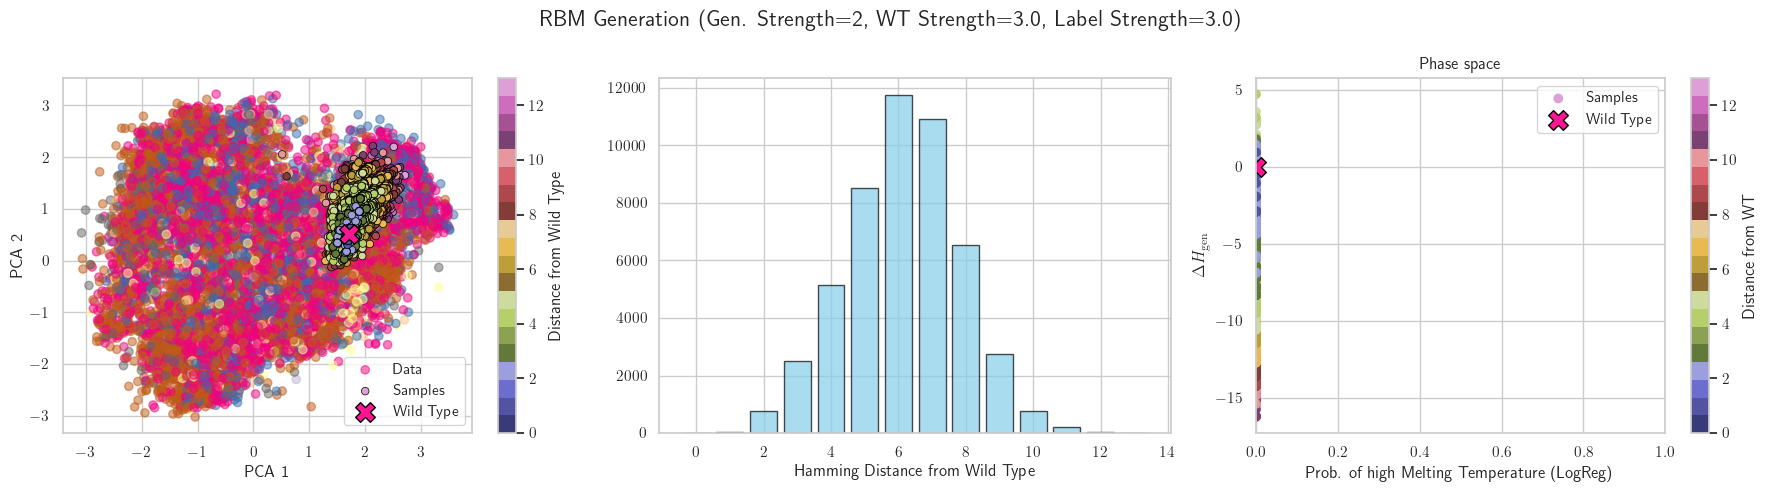

In [23]:
plot_summary(
    samples_pca=pca.transform(cond_samples["visible"].view(len(cond_samples["visible"]), -1).cpu().numpy()),
    wild_type_pca=wt_proj,
    data_pca=data_proj,
    data_labels=labels_data,
    distances=distances,
    energies=energies,
    sample_labels=labels_pred_lr,
    energy_wt=energy_wt,
    label_wt=labels_pred_lr_wt,
    title=f"RBM Generation (Gen. Strength={gen_strength}, WT Strength={wt_strength}, Label Strength={label_strength})"
)

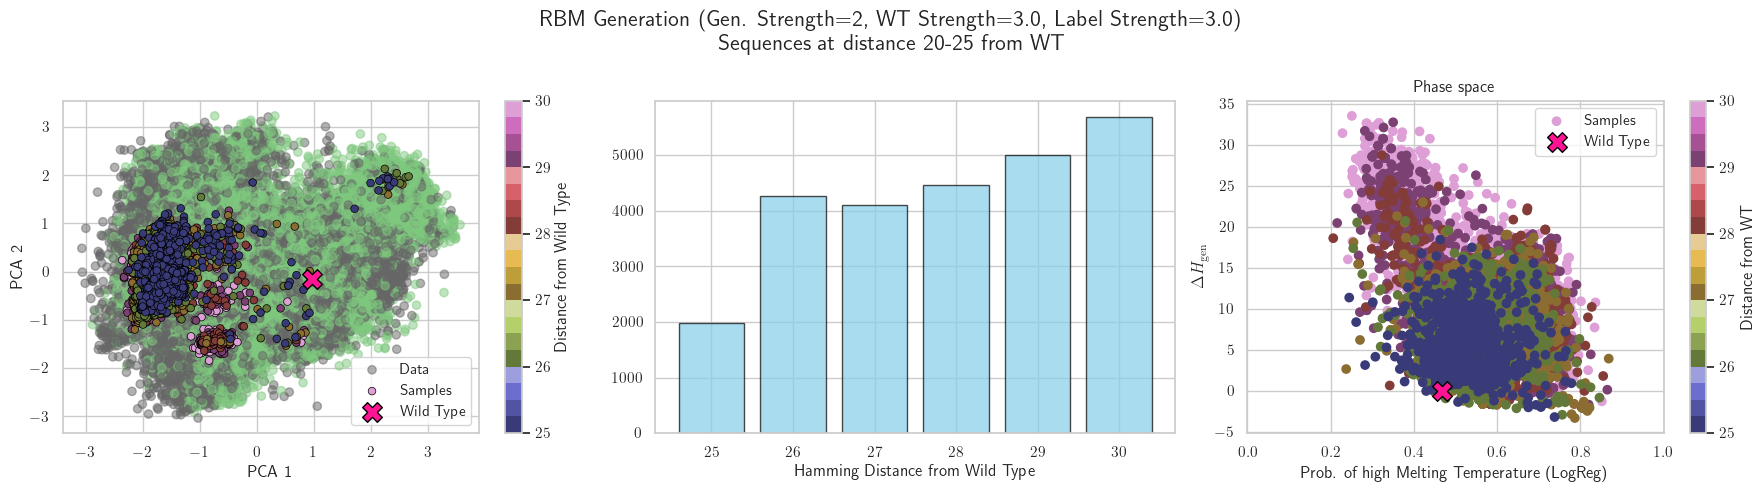

In [42]:
# Keep only sequences at distance 20 - 25
mask = (distances >= 25) & (distances <= 30)
seqs_d = cond_samples["visible"][mask]
labels_pred_rbm_d = labels_pred_rbm[mask]
labels_pred_lr_d = labels_pred_lr[mask]
energies_d = energies[mask]
distances_d = distances[mask]

plot_summary(
    samples_pca=pca.transform(seqs_d.view(len(seqs_d), -1).cpu().numpy()),
    wild_type_pca=wt_proj,
    data_pca=data_proj,
    data_labels=labels_data,
    distances=distances_d,
    energies=energies_d,
    sample_labels=labels_pred_rbm_d,
    energy_wt=energy_wt,
    label_wt=labels_pred_rbm_wt,
    title=f"RBM Generation (Gen. Strength={gen_strength}, WT Strength={wt_strength}, Label Strength={label_strength})\nSequences at distance 20-25 from WT"
)

In [44]:
# select 4 groups of sequences:
# - low energy, low probability
# - low energy, high probability
# - high energy, low probability
# - high energy, high probability
mask1 = (energies_d - energy_wt < 0) & (labels_pred_lr_d < 0.5)
mask2 = (energies_d - energy_wt < 0) & (labels_pred_lr_d >= 0.7)
mask3 = (energies_d - energy_wt >= 5) & (labels_pred_lr_d < 0.5)
mask4 = (energies_d - energy_wt >= 5) & (labels_pred_lr_d >= 0.7)
num_test_max = 100

## Test the generated sequences with the Vienna package

In [45]:
import re
import RNA

def compute_Tm(sequences, tmin=0, tmax=150, tinc=1):
    T_m_list = []
    string_sequences = ["".join(tokens[i] for i in sequence) for sequence in sequences]
    for i, seq in enumerate(string_sequences):
        print(f"Computing Tm for sequence {i+1} of {len(string_sequences)}")
        fc = RNA.fold_compound(seq)
        results = RNA.fold_compound.heat_capacity(fc, tmin, tmax, tinc)
        temperatures = []
        heat_capacities = []
        for result in results:
            # Convert the object to string
            result_str = str(result)
            # Parse the string (assuming format: RNA.RNA.heat_capacity_result(temperature="X", heat_capacity=Y))
            temp_str = float(re.split(r'[ ,"]', str(result))[3])
            hc_str = float(re.split(r'[ ,"]', str(result))[7])

            temperatures.append(temp_str)
            heat_capacities.append(hc_str)

        # Convert to NumPy arrays if needed
        temperatures = np.array(temperatures)
        heat_capacities = np.array(heat_capacities)
        argmax_hc = np.argmax(heat_capacities)
        T_m = temperatures[argmax_hc]
        T_m_list.append(T_m)

    return T_m_list

In [48]:
df_results = pd.DataFrame()

for i, mask in enumerate([mask1, mask2, mask3, mask4]):
    num_test = min(num_test_max, mask.sum())
    print(f"Group {i+1}: Number of sequences to test: {num_test}")
    if num_test == 0:
        raise ValueError(f"No sequences found for group {i+1} with the given criteria.")
    prob_group = labels_pred_lr_d[mask][:num_test]
    distances_group = distances_d[mask][:num_test]
    samples_group = seqs_d[mask][:num_test]
    energies_group = energies_d[mask][:num_test]

    # sort data by increasing distance from wt
    distances_sorted_indices = np.argsort(distances_group)
    prob_group = prob_group[distances_sorted_indices]
    distances_group = distances_group[distances_sorted_indices]
    samples_group = samples_group[distances_sorted_indices]
    energies_group = energies_group[distances_sorted_indices]
    
    test_sequences = samples_group.argmax(dim=-1).cpu().numpy()
    Tm_group = compute_Tm(test_sequences, tmin=0, tmax=150, tinc=1)
    thermoscores_group = compute_thermoscore(dot_bracket_structure, test_sequences)
    thermoscores_group = np.array(thermoscores_group)
    df_temp = pd.DataFrame({
        "Group": [f"Group {i+1}"] * num_test,
        "Tm (ViennaRNA)": Tm_group,
        "Thermoscore (ViennaRNA)": thermoscores_group,
        "Predicted Probability (LR)": prob_group,
        "Distance": distances_group,
        "Energy": energies_group,
    })
    df_results = pd.concat([df_results, df_temp], ignore_index=True)

Group 1: Number of sequences to test: 5
Computing Tm for sequence 1 of 5
Computing Tm for sequence 2 of 5
Computing Tm for sequence 3 of 5
Computing Tm for sequence 4 of 5
Computing Tm for sequence 5 of 5
Group 2: Number of sequences to test: 100
Computing Tm for sequence 1 of 100
Computing Tm for sequence 2 of 100
Computing Tm for sequence 3 of 100
Computing Tm for sequence 4 of 100
Computing Tm for sequence 5 of 100
Computing Tm for sequence 6 of 100
Computing Tm for sequence 7 of 100
Computing Tm for sequence 8 of 100
Computing Tm for sequence 9 of 100
Computing Tm for sequence 10 of 100
Computing Tm for sequence 11 of 100
Computing Tm for sequence 12 of 100
Computing Tm for sequence 13 of 100
Computing Tm for sequence 14 of 100
Computing Tm for sequence 15 of 100
Computing Tm for sequence 16 of 100
Computing Tm for sequence 17 of 100
Computing Tm for sequence 18 of 100
Computing Tm for sequence 19 of 100
Computing Tm for sequence 20 of 100
Computing Tm for sequence 21 of 100
Comput

In [49]:
Tm_wt = compute_Tm(wt.argmax(dim=-1).cpu().numpy().reshape(1, -1), tmin=0, tmax=150, tinc=1)[0]
thermoscore_wt = compute_thermoscore(dot_bracket_structure, [wt.argmax(dim=-1).cpu().numpy()])[0]
print(f"Wild-type Tm: {Tm_wt}")
print(f"Wild-type Thermoscore: {thermoscore_wt}")

Computing Tm for sequence 1 of 1
Wild-type Tm: 95.0
Wild-type Thermoscore: 25.799999237060547


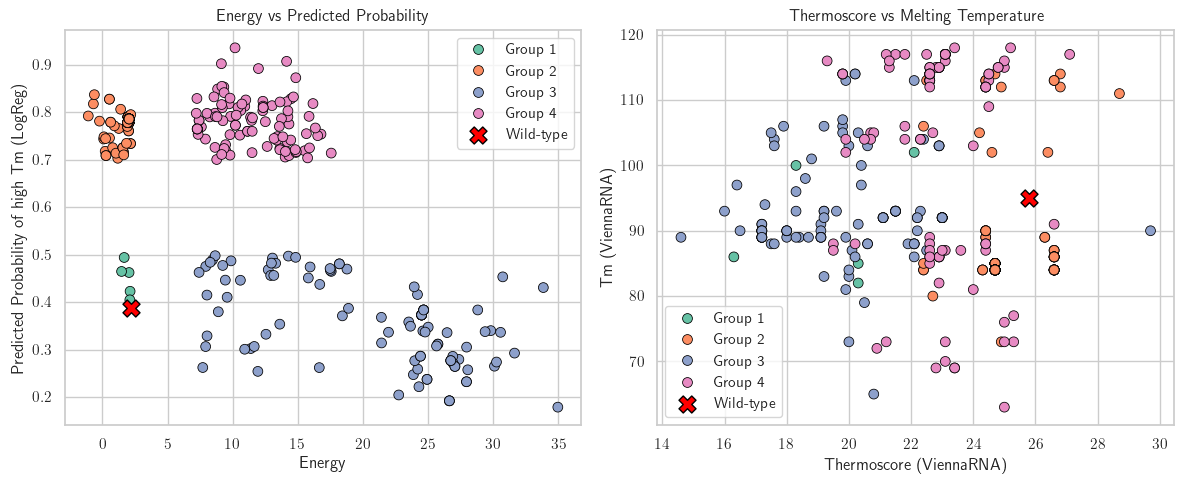

In [50]:
# figure with 2 axes: energy vs probability, thermoscore vs Tm
import seaborn as sns
sns.set(style="whitegrid")

fig, ax = plt.subplots(1, 2, figsize=(12, 5), dpi=100)
ax = ax.flatten()

sns.scatterplot(
    data=df_results,
    x="Energy",
    y="Predicted Probability (LR)",
    hue="Group",
    palette="Set2",
    alpha=1.0,
    edgecolor='black',
    s=50,
    ax=ax[0]
)
ax[0].scatter(energy_wt, labels_pred_lr_wt, color='red', s=150, edgecolor='black', label='Wild-type', marker='X')
ax[0].set_ylabel("Predicted Probability of high Tm (LogReg)")
ax[0].legend()
ax[0].set_title("Energy vs Predicted Probability")

sns.scatterplot(
    data=df_results,
    y="Tm (ViennaRNA)",
    x="Thermoscore (ViennaRNA)",
    hue="Group",
    palette="Set2",
    alpha=1.0,
    edgecolor='black',
    s=50,
    ax=ax[1]
)
ax[1].scatter(thermoscore_wt, Tm_wt, color='red', s=150, edgecolor='black', label='Wild-type', marker='X')
ax[1].set_xlabel("Thermoscore (ViennaRNA)")
ax[1].legend()
ax[1].set_title("Thermoscore vs Melting Temperature")

plt.tight_layout()